In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("C:\Customer_Churn_Analysis\Data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [2]:
# Display the data type of each column
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


In [3]:
# Display descriptive statistics for numerical columns
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [2]:
# Count the number of unique values in each column
df.nunique()

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6531
Churn                  2
dtype: int64

In [5]:
# Count customers by gender
gender_counts = df["gender"].value_counts()

print(gender_counts)

Male      3555
Female    3488
Name: gender, dtype: int64


In [6]:
# Calculate the percentage of customers by gender
gender_percentage = df["gender"].value_counts(normalize=True) * 100

print(gender_percentage)

Male      50.47565
Female    49.52435
Name: gender, dtype: float64


In [7]:
# Analyze churn distribution by gender
gender_churn = pd.crosstab(
    df["gender"],
    df["Churn"],
    normalize="index"
) * 100

print(gender_churn)

Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338


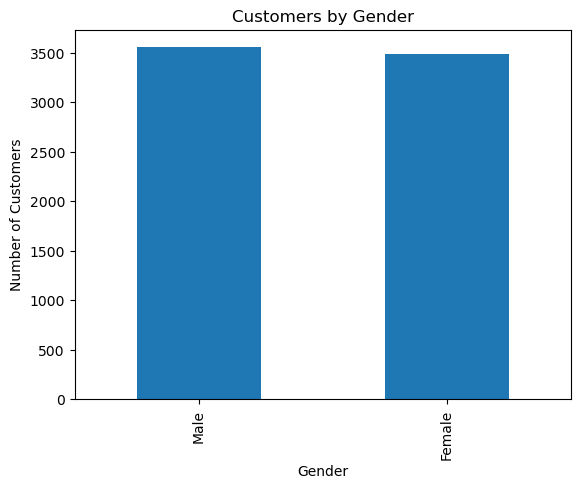

In [8]:
import matplotlib.pyplot as plt

# Count customers by gender
gender_counts = df["gender"].value_counts()

# Create a bar chart
gender_counts.plot(kind="bar")

# Add chart title and labels
plt.title("Customers by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [9]:
# Count customers by senior citizen status
senior_counts = df["SeniorCitizen"].value_counts()

print(senior_counts)

0    5901
1    1142
Name: SeniorCitizen, dtype: int64


In [10]:
# Analyze churn by senior citizen status
senior_churn = pd.crosstab(
    df["SeniorCitizen"],
    df["Churn"],
    normalize="index"
) * 100

print(senior_churn)


Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261


In [11]:
# Count customers by contract type
contract_counts = df["Contract"].value_counts()

print(contract_counts)

Month-to-month    3875
Two year          1695
One year          1473
Name: Contract, dtype: int64


In [12]:
# Calculate churn percentage for each contract type
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [3]:
# Calculate MonthlyCharges statistics by churn status
monthly_charges_summary = df.groupby("Churn")["MonthlyCharges"].agg(
    ["min", "mean", "median", "max"]
)

print(monthly_charges_summary)

         min       mean  median     max
Churn                                  
No     18.25  61.265124  64.425  118.75
Yes    18.85  74.441332  79.650  118.35


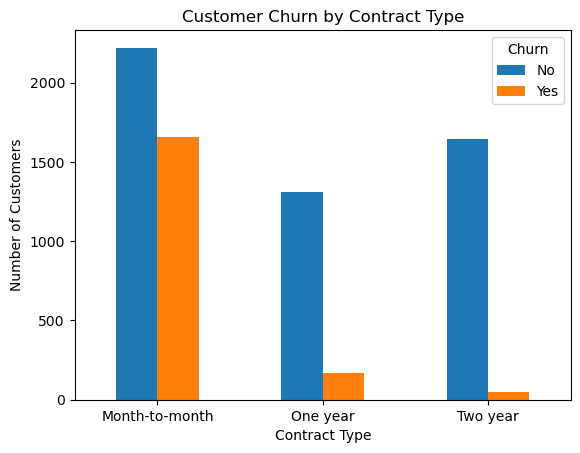

In [13]:
# Create a cross-tabulation of contract type and churn
contract_churn_counts = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

# Create a bar chart
contract_churn_counts.plot(kind="bar")

# Add chart title and labels
plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

# Rotate x-axis labels for better readability
plt.xticks(rotation=0)

# Display the chart
plt.show()


In [14]:
# Display basic statistics for customer tenure
print(df["tenure"].describe())

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


In [15]:
# Compare average tenure between churned and non-churned customers
tenure_churn = df.groupby("Churn")["tenure"].mean()

print(tenure_churn)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [2]:
# Create a summary of customer tenure by churn status
df.groupby("Churn")["tenure"].agg(
    ["min", "mean", "median", "max"]
)

,min,mean,median,max
Churn,,,,
No,0,37.569965,38.0,72
Yes,1,17.979133,10.0,72


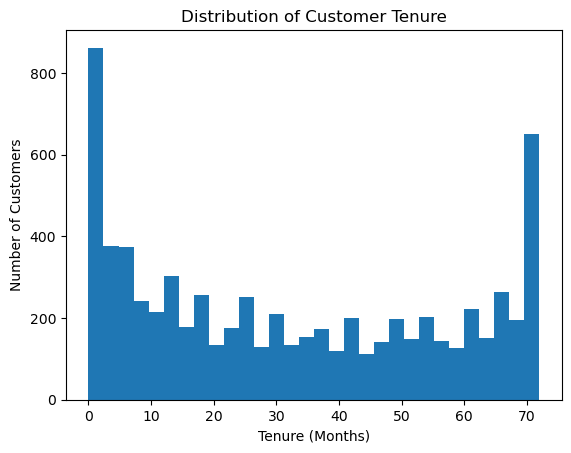

In [16]:
# Create a histogram of customer tenure
df["tenure"].plot(kind="hist", bins=30)

# Add chart title and labels
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

# Display the chart
plt.show()

In [17]:
# Compare average monthly charges by churn status
monthly_charges_churn = df.groupby("Churn")["MonthlyCharges"].mean()

print(monthly_charges_churn)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


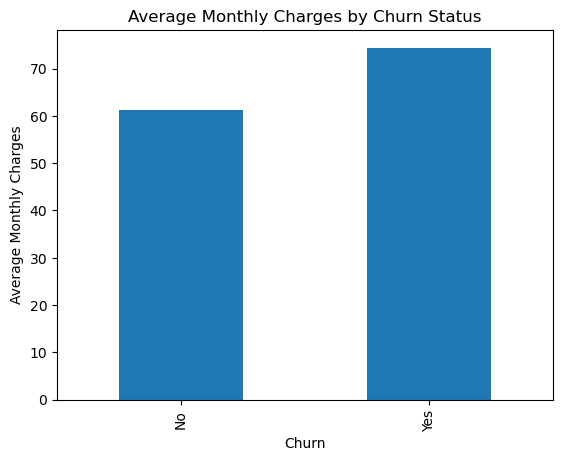

In [18]:

# Create a bar chart for average monthly charges by churn
monthly_charges_churn.plot(kind="bar")

# Add chart title and labels
plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Average Monthly Charges")

# Display the chart
plt.show()

## Day 2 Findings

### Gender and Churn
- Female customers have a churn rate of 26.92%.
- Male customers have a churn rate of 26.16%.
- The difference is small, so gender does not show a strong association with churn.

### Senior Citizen and Churn
- Senior citizens have a churn rate of 41.68%.
- Non-senior customers have a churn rate of 23.61%.
- Senior citizen status shows a noticeable association with churn.

### Contract Type and Churn
- Month-to-month customers have the highest churn rate at 42.71%.
- One-year contract customers have a churn rate of 11.27%.
- Two-year contract customers have the lowest churn rate at 2.83%.
- Contract type appears to be an important factor associated with churn.

### Tenure and Churn
- Customers who churned have an average tenure of 17.98 months.
- Customers who remained have an average tenure of 37.57 months.
- The median tenure was 10 months for churned customers and 38 months for customers who remained.
- Shorter tenure is strongly associated with churn.

### Monthly Charges and Churn
- Customers who churned have an average monthly charge of 74.44.
- Customers who remained have an average monthly charge of 61.27.
- The median monthly charge was 79.65 for churned customers and 64.43 for customers who remained.
- Higher monthly charges are associated with higher churn in this dataset.